# Lab 10-05 · Amplifier Fundamentals

Companion to [chapter 10-05](../../chapters/10-05-amplifier-fundamentals.md). Predict first; the `assert` lines check against the answer keys.

In [1]:
import math
import itertools
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import iv
VT = 1.380649e-23 * 300 / 1.602176634e-19

def cascade(stages, r_sig, r_load):
    """Overall gain of unilateral voltage-amplifier stages (R_i, A_vo, R_o) between a source and a load."""
    g, r_prev = 1.0, r_sig
    for r_i, a_vo, r_o in stages:
        g *= r_i / (r_i + r_prev) * a_vo
        r_prev = r_o
    return g * r_load / (r_load + r_prev)

## Part 1 · Bridging against matching (guided exercise)

Example 10-05.2's amplifier ($A_{vo}$ = 200, $R_i$ = 10 kΩ, $R_o$ = 2 kΩ) from a 5 kΩ source at 10 mV rms. *Predict first:* the load for maximum power, and the gain there.

max power 0.2222 mW at R_L = 2.000 kOhm, gain there 66.66


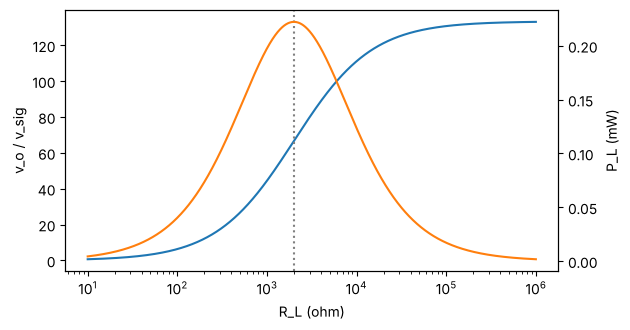

In [2]:
r_load = np.logspace(1, 6, 20001)
gain = np.array([cascade([(10e3, 200, 2e3)], 5e3, rl) for rl in r_load])
p_load = (0.01 * gain) ** 2 / r_load
k = p_load.argmax()
print(f"max power {p_load[k]*1e3:.4f} mW at R_L = {r_load[k]/1e3:.3f} kOhm, gain there {gain[k]:.2f}")
assert abs(r_load[k] / 1e3 - 2) < 5e-3 and abs(p_load[k] * 1e3 - 0.222) < 5e-4 and abs(gain[k] - 66.7) < 0.05
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.semilogx(r_load, gain, label="voltage gain"); ax.set_xlabel("R_L (ohm)"); ax.set_ylabel("v_o / v_sig")
ax2 = ax.twinx(); ax2.semilogx(r_load, p_load * 1e3, color="C1", label="load power"); ax2.set_ylabel("P_L (mW)")
ax.axvline(2e3, ls=":", color="0.5"); fig.tight_layout(); plt.show()

## Part 2 · The best order for three stages

*Predict first:* which of the six orders of X, Y and the buffer Z is best?

In [3]:
stages = {"X": (1e6, 10, 10e3), "Y": (2e3, 100, 100), "Z": (100e3, 1, 50)}
results = sorted(((cascade([stages[c] for c in order], 50e3, 1e3), "".join(order))
                  for order in itertools.permutations("XYZ")), reverse=True)
for g, name in results:
    print(f"{name}: {g:9.3f}  ({20*math.log10(g):6.2f} dB)")
assert results[0][1] == "XZY" and abs(results[0][0] - 767.9) < 0.05
assert results[-1][1] == "YZX" and abs(results[-1][0] - 3.493) < 5e-4

XZY:   767.894  ( 57.71 dB)
XYZ:   151.021  ( 43.58 dB)
ZXY:   101.005  ( 40.09 dB)
ZYX:    59.122  ( 35.43 dB)
YXZ:    33.297  ( 30.45 dB)
YZX:     3.493  ( 10.86 dB)


## Part 3 · Swing and efficiency of a real class-A stage

The common-emitter stage of Figure 2: $I_C$ = 1 mA at rest, $R_C$ = 5 kΩ, $V_{CC}$ = 10 V. With $v_{be} = \hat v\cos\theta$ and $x = \hat v/V_T$, the collector current is $I_Ce^{x\cos\theta}$, whose fundamental is $2I_1(x)I_C$ and average $I_0(x)I_C$.

10 mV: fundamental 1.9705 V, signal 0.3883 mW, supply 10.378 mW, efficiency 3.742%
saturation first reached at 17.397 mV input; positive peak 7.4490 V


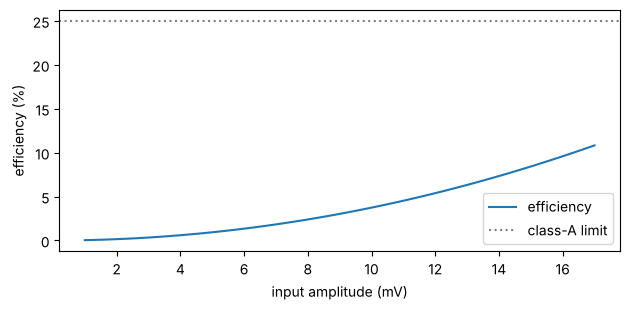

In [4]:
def stage(v_hat):
    x = v_hat / VT
    fund = 5e3 * 1e-3 * 2 * iv(1, x)                  # output fundamental amplitude (V)
    p_sig = fund ** 2 / (2 * 5e3)
    p_dc = 10 * 1e-3 * iv(0, x)
    return fund, p_sig, p_dc, p_sig / p_dc
f, ps, pd, eta = stage(10e-3)
print(f"10 mV: fundamental {f:.4f} V, signal {ps*1e3:.4f} mW, supply {pd*1e3:.3f} mW, efficiency {eta*100:.3f}%")
assert abs(f - 1.970) < 5e-4 and abs(ps * 1e3 - 0.388) < 5e-4 and abs(pd * 1e3 - 10.38) < 5e-3 and abs(eta * 100 - 3.74) < 5e-3
# the input amplitude at which the minimum collector voltage first reaches V_CE,sat = 0.2 V
v_sat = VT * math.log(1 + (5 - 0.2) / 5)
pos_peak = 5 + 5 * (1 - math.exp(-v_sat / VT))
print(f"saturation first reached at {v_sat*1e3:.3f} mV input; positive peak {pos_peak:.4f} V")
assert abs(v_sat * 1e3 - 17.40) < 5e-3 and abs(pos_peak - 7.449) < 5e-4
amps = np.linspace(1e-3, 17e-3, 60)
plt.figure(figsize=(6.4, 3.2))
plt.plot(amps * 1e3, [stage(a)[3] * 100 for a in amps], label="efficiency")
plt.axhline(25, ls=":", color="0.5", label="class-A limit")
plt.xlabel("input amplitude (mV)"); plt.ylabel("efficiency (%)"); plt.legend(); plt.tight_layout(); plt.show()

## Part 4 · Front-end frequency response

Example 10-05.7: midband gain 1296, a 330 nF capacitor between the 100 kΩ sensor and the 10 MΩ buffer.

midband 1296.3; gain at 0.1 Hz 1169.7, at 1 Hz 1294.8


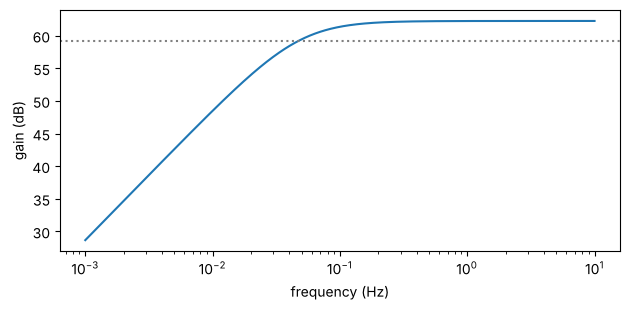

In [5]:
f = np.logspace(-3, 1, 400)
w = 2 * np.pi * f
c, r_s, r_i = 330e-9, 100e3, 10e6
h_in = r_i / (r_s + r_i + 1 / (1j * w * c))            # input network with the capacitor
mid = cascade([(10e6, 1, 100), (10e3, 40, 1e3), (10e3, 40, 1e3)], 100e3, 10e3)
gain = np.abs(h_in / (r_i / (r_s + r_i)) * mid)
def g_at(fr):
    h = r_i / (r_s + r_i + 1 / (1j * 2 * np.pi * fr * c))
    return abs(h / (r_i / (r_s + r_i)) * mid)
print(f"midband {mid:.1f}; gain at 0.1 Hz {g_at(0.1):.1f}, at 1 Hz {g_at(1.0):.1f}")
assert abs(g_at(0.1) - 1170) < 0.5 and abs(g_at(1.0) - 1295) < 0.5
plt.figure(figsize=(6.4, 3.2)); plt.semilogx(f, 20 * np.log10(gain))
plt.axhline(20 * math.log10(mid) - 3.01, ls=":", color="0.5")
plt.xlabel("frequency (Hz)"); plt.ylabel("gain (dB)"); plt.tight_layout(); plt.show()